# FINRISK Colombia: exploración y auditoría de resultados agregados

**Primera entrega — Despliegue de soluciones analíticas**  
**Preparado para revisión del equipo: 24 de octubre de 2026**

Este cuaderno organiza y explora los resultados que el equipo compartió en FINRISK.zip. El panel financiero resumido corresponde a **2019–2024**. Los archivos individuales no estaban incluidos y Joaquín confirmó que aún no dispone de ellos.

**Alcance de la ejecución guardada:** lectura de cuatro CSV agregados, verificaciones aritméticas, tablas, cinco figuras e interpretación. Se recalculan porcentajes y visualizaciones desde esos archivos. No se volvió a ejecutar la consolidación original ni se verificaron los registros de cada empresa.

El corte de insolvencia de octubre de 2026 se analiza aparte: su universo no equivale al panel financiero 2019–2024. No hay una etiqueta histórica validada ni resultados predictivos en este cuaderno.

## 1. Pregunta de negocio y propósito

FINRISK busca apoyar al analista bancario en la evaluación del riesgo de ingreso futuro a un proceso formal de insolvencia. Una estimación de ese evento sería un insumo para su evaluación; no basta para decidir automáticamente si concede un crédito.

**Pregunta de esta exploración:** ¿qué cobertura, calidad y patrones anuales muestran los datos financieros preliminares, y qué limitaciones deben resolverse antes de construir una muestra de entrenamiento sobre insolvencia futura?

Se revisan cobertura anual, calidad y selección descriptiva, cuatro razones financieras, alcance del cruce preliminar y requisitos para ampliar el análisis individual. El horizonte de doce meses continúa siendo una propuesta por validar. No se entrena un modelo aquí.

## 2. Insumos disponibles y trazabilidad

| Archivo en data/agregados | Unidad y contenido | Qué permite |
| --- | --- | --- |
| cobertura_y_calidad_por_anio.csv | Año financiero; seis registros | Cobertura, controles y filtro descriptivo |
| estadisticos_indicadores_por_anio.csv | Año–indicador; 24 registros | Medias, medianas, percentiles y extremos ya calculados |
| incidencias_calidad.csv | Tipo de incidencia; ocho registros | Frecuencias de señales que pueden solaparse |
| resumen_cruce.csv | Métrica; 21 registros | Leer el alcance del cruce previo |
| resumen_analisis.txt y RESUMEN_VALIDACION.txt | Resúmenes previos | Contrastar totales declarados y límites |

Los archivos conservan los mismos bytes recibidos. Sus huellas SHA-256 identifican la versión analizada. Su tamaño pequeño **no representa** el volumen original.

Fuentes originales citadas por el equipo: [Situación financiera NIIF](https://www.datos.gov.co/d/pfdp-zks5), [Resultado integral NIIF](https://www.datos.gov.co/d/prwj-nzxa) e [informes de insolvencia](https://www.supersociedades.gov.co/web/procedimientos-de-insolvencia/informes). Esta ejecución no descarga esas bases ni verifica sus versiones actuales.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import re
import sys
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown, Image

# Localización relativa: abrir desde la raíz o desde notebooks/.
candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in candidates if (p / "data/agregados/cobertura_y_calidad_por_anio.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Extraiga la carpeta completa y abra el notebook desde ella o desde notebooks/.")
DATA = ROOT / "data/agregados"
TABLES = ROOT / "results/tablas"
FIGURES = ROOT / "results/figuras"
for folder in [TABLES, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

INDICADORES = ["endeudamiento", "liquidez_corriente", "roa", "margen_neto"]
ETIQUETAS = {"endeudamiento": "Endeudamiento", "liquidez_corriente": "Liquidez corriente",
             "roa": "ROA", "margen_neto": "Margen neto"}
PALETTE = {"navy": "#193A57", "blue": "#347CA5", "teal": "#23877D", "orange": "#BD762B", "gray": "#64748B"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)

def numero_es(value, decimals=0):
    return f"{value:,.{decimals}f}".replace(",", "@").replace(".", ",").replace("@", ".")

def guardar_tabla(df, name):
    df.to_csv(TABLES / f"{name}.csv", index=False, encoding="utf-8")

def mostrar_figura(fig, name):
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

versiones = {"Python": platform.python_version()}
for name in ["pandas", "numpy", "matplotlib", "nbformat", "nbclient", "ipykernel"]:
    versiones[name] = metadata.version(name)
display(pd.DataFrame(versiones.items(), columns=["Componente", "Versión"]))

,Componente,Versión
0,Python,3.12.14
1,pandas,2.3.3
2,numpy,2.5.4
3,matplotlib,3.11.2
4,nbformat,5.11.1
5,nbclient,0.11.0
6,ipykernel,7.4.0


In [2]:
coverage = pd.read_csv(DATA / "cobertura_y_calidad_por_anio.csv", encoding="utf-8-sig")
stats = pd.read_csv(DATA / "estadisticos_indicadores_por_anio.csv", encoding="utf-8-sig")
issues = pd.read_csv(DATA / "incidencias_calidad.csv", encoding="utf-8-sig")
crossing = pd.read_csv(DATA / "resumen_cruce.csv", sep=";", encoding="utf-8-sig", dtype="string")
text_summary = (DATA / "resumen_analisis.txt").read_text(encoding="utf-8-sig")
text_validation = (DATA / "RESUMEN_VALIDACION.txt").read_text(encoding="utf-8-sig")

frames = {"cobertura_y_calidad_por_anio.csv": coverage,
          "estadisticos_indicadores_por_anio.csv": stats,
          "incidencias_calidad.csv": issues, "resumen_cruce.csv": crossing}
manifest = []
for path in sorted(DATA.iterdir()):
    if path.is_file():
        manifest.append({"archivo": path.name, "bytes": path.stat().st_size,
                         "filas_tabulares": len(frames[path.name]) if path.name in frames else None,
                         "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
manifest = pd.DataFrame(manifest)
display(manifest)
guardar_tabla(manifest, "trazabilidad_insumos")

,archivo,bytes,filas_tabulares,sha256
0,cobertura_y_calidad_por_anio.csv,703,6.0,9e5bf74f267e026ebbeacc232e381c87a9fff8444cb744091c389c5b61022892
1,estadisticos_indicadores_por_anio.csv,4106,24.0,54323e7b5f688aa742cda1ba26c66bab561ec74883d867685f1e7209eef09859
2,incidencias_calidad.csv,354,8.0,fb45275e42b3ac66a422160cd93114838fbedbb95dc687244eb73a2db4a59410
3,resumen_analisis.txt,1221,NaN,8ef72a7041f1c55cc5d6ab28e3a1c4c30c73da8463f20e7f56788248e8a1d0c2
4,resumen_cruce.csv,1552,21.0,1235f3895532776a038d270f1d05482a169e796d8fda43302ad32ace93ce4f73
5,RESUMEN_VALIDACION.txt,912,NaN,dd97ae26b21cd11487a759147259b932de5b4e8b897087e87fcf20ca1c03dc18


## 3. Diccionario mínimo y controles

La unidad principal es **empresa–año**. Una empresa puede aparecer en varios ejercicios: sumar los conteos anuales no produce empresas únicas del periodo.

| Campo | Interpretación | Unidad |
| --- | --- | --- |
| observaciones / empresas | Registros / NIT distintos dentro del año, según el procesamiento previo | Conteo anual |
| cuatro_indicadores | Filas con las cuatro razones financieras finitas | Conteo y porcentaje anual |
| balances_cuadrados | Balance dentro de tolerancia relativa del 1 % usada previamente | Conteo y porcentaje anual |
| con_discrepancia | Empresa–año con candidatos contables en conflicto | Conteo y porcentaje anual |
| filas_validas_descriptivo | Filtro estricto provisional | Conteo y porcentaje anual |
| endeudamiento | Pasivo total / activo total | Fracción original; % en gráficos |
| liquidez_corriente | Activo corriente / pasivo corriente | Veces |
| roa | Utilidad neta / activo total | Fracción original; % en gráficos |
| margen_neto | Utilidad neta / ingresos | Fracción original; % en gráficos |
| n de estadísticos | Observaciones de la muestra estricta del año | Empresa–año |

Hay que revisar denominadores, versiones contables y unidades. No se reemplazan signos negativos por cero ni se corrigen escalas automáticamente.

In [3]:
required = {
    "coverage": {"anio_financiero", "empresas", "observaciones", "cuatro_indicadores", "balances_cuadrados",
                 "con_discrepancia", "activos_positivos", "ingresos_positivos", "filas_validas_descriptivo",
                 "pct_cuatro_indicadores", "pct_balances_cuadrados", "pct_con_discrepancia", "pct_filas_validas_descriptivo"},
    "stats": {"anio_financiero", "indicador", "n", "media", "mediana", "p05", "p25", "p75", "p95", "minimo", "maximo"},
    "issues": {"tipo_incidencia", "registros", "porcentaje"},
    "crossing": {"indicador", "valor"},
}
for name in required:
    frame = globals()[name]
    missing = required[name] - set(frame.columns)
    if missing:
        raise ValueError(f"Faltan columnas en {name}: {sorted(missing)}")
    if frame.isna().any().any():
        raise ValueError(f"Hay celdas faltantes en el agregado {name}; revise antes de continuar.")

for frame, text_columns in [(coverage, set()), (stats, {"indicador"}), (issues, {"tipo_incidencia"})]:
    for col in frame.columns:
        if col not in text_columns:
            frame[col] = pd.to_numeric(frame[col], errors="raise")
            if not np.isfinite(frame[col]).all():
                raise ValueError(f"La columna {col} contiene valores no finitos.")
coverage = coverage.sort_values("anio_financiero").reset_index(drop=True)
stats = stats.sort_values(["anio_financiero", "indicador"]).reset_index(drop=True)

assert not coverage["anio_financiero"].duplicated().any(), "Año duplicado en cobertura."
assert not stats.duplicated(["anio_financiero", "indicador"]).any(), "Año-indicador duplicado."
assert not issues["tipo_incidencia"].duplicated().any(), "Incidencia duplicada."
assert not crossing["indicador"].duplicated().any(), "Métrica de cruce duplicada."
assert set(stats["indicador"]) == set(INDICADORES)
assert set(stats["anio_financiero"]) == set(coverage["anio_financiero"])
assert stats.groupby("anio_financiero")["indicador"].nunique().eq(4).all()
for col in ["empresas", "observaciones", "cuatro_indicadores", "balances_cuadrados", "con_discrepancia",
            "activos_positivos", "ingresos_positivos", "filas_validas_descriptivo"]:
    assert (coverage[col] >= 0).all() and (coverage[col] % 1 == 0).all(), f"Conteo inválido: {col}"
    if col != "observaciones":
        assert (coverage[col] <= coverage["observaciones"]).all(), f"Conteo excede denominador: {col}"
assert (coverage["observaciones"] > 0).all()
assert (stats["n"] > 0).all() and (stats["n"] % 1 == 0).all()
assert (issues["registros"] >= 0).all() and (issues["registros"] % 1 == 0).all()
assert (issues["registros"] <= coverage["observaciones"].sum()).all()

checks = []
for count in ["cuatro_indicadores", "balances_cuadrados", "con_discrepancia", "filas_validas_descriptivo"]:
    computed = (100 * coverage[count] / coverage["observaciones"]).round(2)
    difference = (computed - coverage["pct_" + count]).abs().max()
    checks.append({"control": f"Porcentaje anual: {count}", "cumple": bool(difference < 1e-8)})
joined = stats.merge(coverage[["anio_financiero", "filas_validas_descriptivo"]], on="anio_financiero", validate="many_to_one")
checks.append({"control": "n de estadísticos = muestra estricta del año", "cumple": bool(joined["n"].eq(joined["filas_validas_descriptivo"]).all())})
quantiles = stats[["minimo", "p05", "p25", "mediana", "p75", "p95", "maximo"]].to_numpy()
checks.append({"control": "Orden de percentiles y extremos", "cumple": bool((np.diff(quantiles, axis=1) >= 0).all())})
checks.append({"control": "Media dentro de los extremos", "cumple": bool(stats["media"].between(stats["minimo"], stats["maximo"]).all())})
computed_issues_pct = (100 * issues["registros"] / coverage["observaciones"].sum()).round(2)
checks.append({"control": "Porcentaje de incidencias sobre todas las empresa-año", "cumple": bool(np.allclose(computed_issues_pct, issues["porcentaje"], atol=1e-8))})
checks = pd.DataFrame(checks)
display(checks)
assert checks["cumple"].all(), "Hay diferencias entre los agregados recibidos; revise antes de continuar."
guardar_tabla(checks, "controles_agregados")
print("Estos controles verifican la coherencia interna de los resúmenes; no verifican registros individuales.")

,control,cumple
0,Porcentaje anual: cuatro_indicadores,True
1,Porcentaje anual: balances_cuadrados,True
2,Porcentaje anual: con_discrepancia,True
3,Porcentaje anual: filas_validas_descriptivo,True
4,n de estadísticos = muestra estricta del año,True
5,Orden de percentiles y extremos,True
6,Media dentro de los extremos,True
7,Porcentaje de incidencias sobre todas las empresa-año,True


Estos controles verifican la coherencia interna de los resúmenes; no verifican registros individuales.


## 4. Cobertura y muestra descriptiva

El filtro previo requiere simultáneamente cuatro indicadores finitos, balance dentro de la tolerancia, ausencia de candidatos en conflicto, activos positivos e ingresos positivos. Es una regla provisional para describir razones comparables; podría excluir empresas en crisis y **no define la población para entrenar**.

Los controles se superponen. Se puede calcular la diferencia entre total y filtro estricto; no se puede atribuir a causas excluyentes sumando incidencias.

In [4]:
TOTAL = int(coverage["observaciones"].sum())
STRICT = int(coverage["filas_validas_descriptivo"].sum())
summary_rows = []
for label, col in [("Con cuatro indicadores", "cuatro_indicadores"), ("Balance dentro de tolerancia", "balances_cuadrados"),
                   ("Con candidatos en conflicto", "con_discrepancia"), ("Con activos positivos", "activos_positivos"),
                   ("Con ingresos positivos", "ingresos_positivos"), ("Filtro descriptivo estricto", "filas_validas_descriptivo")]:
    value = int(coverage[col].sum())
    summary_rows.append({"Concepto": label, "Empresa-año": value, "% del total": 100 * value / TOTAL})
summary_rows.extend([{"Concepto": "Total del panel resumido", "Empresa-año": TOTAL, "% del total": 100.0},
                     {"Concepto": "Fuera del filtro estricto", "Empresa-año": TOTAL - STRICT, "% del total": 100 * (TOTAL - STRICT) / TOTAL}])
summary = pd.DataFrame(summary_rows)
display(summary.round({"% del total": 2}))
guardar_tabla(summary, "resumen_panel")

unique_match = re.search(r"Empresas distintas:\s*([0-9,]+)", text_summary)
unique_reported = int(unique_match.group(1).replace(",", "")) if unique_match else None
source_total = pd.to_numeric(crossing.loc[crossing["indicador"].str.endswith(" - filas validas"), "valor"], errors="raise").sum()
display(Markdown(f"El panel resumido contiene **{numero_es(TOTAL)} empresa–año**. El TXT declara "
                 f"**{numero_es(unique_reported)} empresas distintas**; ese conteo no puede recalcularse "
                 f"con los agregados anuales. Las dos fuentes originales reportan **{numero_es(source_total)} "
                 "filas en formato largo**: conceptos contables, no empresas adicionales."))

,Concepto,Empresa-año,% del total
0,Con cuatro indicadores,162073,91.74
1,Balance dentro de tolerancia,175550,99.37
2,Con candidatos en conflicto,713,0.40
3,Con activos positivos,175802,99.51
4,Con ingresos positivos,163463,92.53
5,Filtro descriptivo estricto,161411,91.37
6,Total del panel resumido,176666,100.00
7,Fuera del filtro estricto,15255,8.63


El panel resumido contiene **176.666 empresa–año**. El TXT declara **37.231 empresas distintas**; ese conteo no puede recalcularse con los agregados anuales. Las dos fuentes originales reportan **27.729.765 filas en formato largo**: conceptos contables, no empresas adicionales.

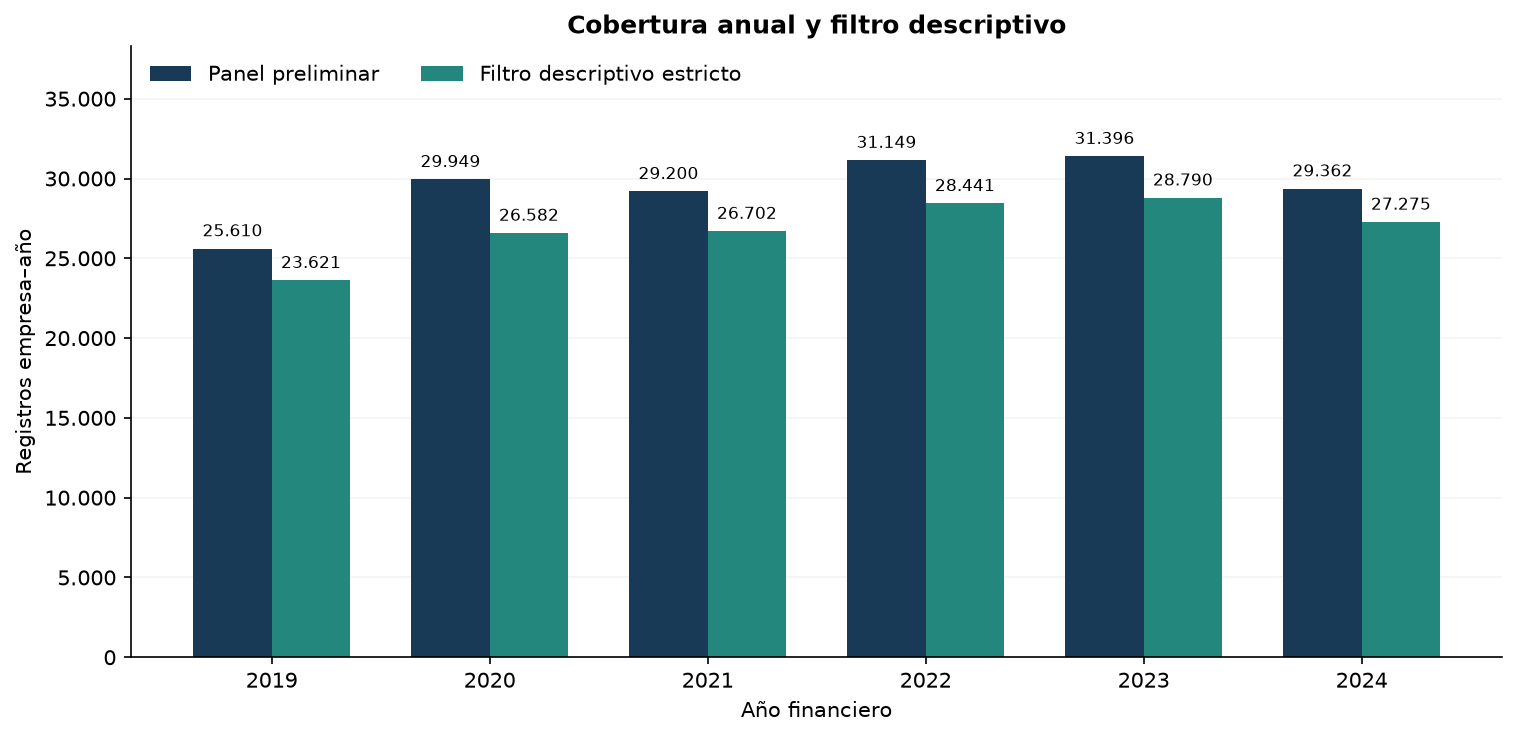

,anio_financiero,observaciones,filas_validas_descriptivo,fuera_filtro_estricto,variacion_cobertura_pct
0,2019,25610,23621,1989,NaN
1,2020,29949,26582,3367,16.94
2,2021,29200,26702,2498,-2.50
3,2022,31149,28441,2708,6.67
4,2023,31396,28790,2606,0.79
5,2024,29362,27275,2087,-6.48


En 2024, la cobertura cambia **-6,48 %** frente al año anterior. Describe registros disponibles; no demuestra cierres, quiebras ni cambios de riesgo en las mismas empresas. La composición anual puede variar.

In [5]:
years = coverage["anio_financiero"].astype(int).astype(str).tolist()
x = np.arange(len(years))
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
b1 = ax.bar(x - .18, coverage["observaciones"], .36, color=PALETTE["navy"], label="Panel preliminar")
b2 = ax.bar(x + .18, coverage["filas_validas_descriptivo"], .36, color=PALETTE["teal"], label="Filtro descriptivo estricto")
for bars in [b1, b2]:
    ax.bar_label(bars, labels=[numero_es(p.get_height()) for p in bars], padding=4, fontsize=8)
ax.set_xticks(x, years)
ax.set(title="Cobertura anual y filtro descriptivo", xlabel="Año financiero", ylabel="Registros empresa–año")
ax.set_ylim(0, coverage["observaciones"].max() * 1.22)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: numero_es(v)))
ax.legend(loc="upper left", frameon=False, ncols=2)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=.15)
mostrar_figura(fig, "01_cobertura_anual")

coverage_analysis = coverage.copy()
coverage_analysis["variacion_cobertura_pct"] = coverage_analysis["observaciones"].pct_change() * 100
coverage_analysis["fuera_filtro_estricto"] = coverage_analysis["observaciones"] - coverage_analysis["filas_validas_descriptivo"]
display(coverage_analysis[["anio_financiero", "observaciones", "filas_validas_descriptivo", "fuera_filtro_estricto", "variacion_cobertura_pct"]].round(2))
guardar_tabla(coverage_analysis, "cobertura_recalculada")
last = coverage_analysis.iloc[-1]
display(Markdown(f"En {int(last['anio_financiero'])}, la cobertura cambia **{numero_es(last['variacion_cobertura_pct'], 2)} %** "
                 "frente al año anterior. Describe registros disponibles; no demuestra cierres, quiebras ni "
                 "cambios de riesgo en las mismas empresas. La composición anual puede variar."))

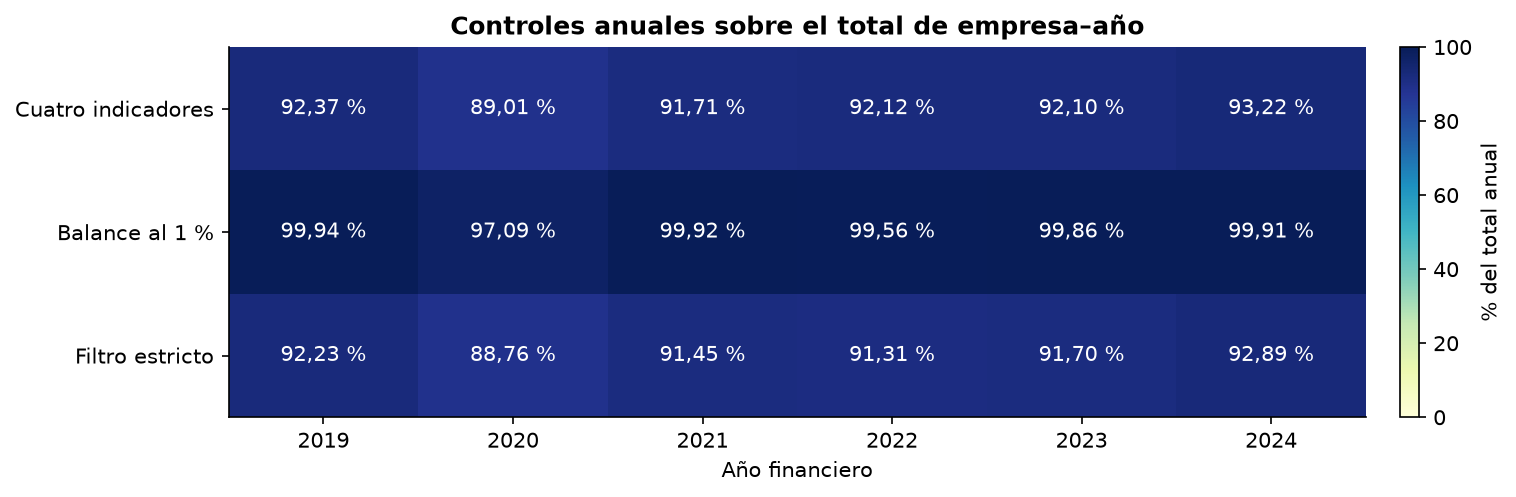

El menor porcentaje del filtro estricto corresponde a **2020 (88,76 %)**. Conviene revisar las filas descartadas y su composición antes de adoptar filtros de entrenamiento.

In [6]:
quality_columns = ["pct_cuatro_indicadores", "pct_balances_cuadrados", "pct_filas_validas_descriptivo"]
quality_labels = ["Cuatro indicadores", "Balance al 1 %", "Filtro estricto"]
quality_values = coverage[quality_columns].to_numpy().T
fig, ax = plt.subplots(figsize=(10, 3.2), layout="constrained")
im = ax.imshow(quality_values, cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
for i in range(quality_values.shape[0]):
    for j in range(quality_values.shape[1]):
        ax.text(j, i, numero_es(quality_values[i, j], 2) + " %", ha="center", va="center", color="white", fontsize=10)
ax.set_xticks(np.arange(len(years)), years)
ax.set_yticks(range(3), quality_labels)
ax.set(title="Controles anuales sobre el total de empresa–año", xlabel="Año financiero")
cbar = fig.colorbar(im, ax=ax, fraction=.035, pad=.03)
cbar.set_label("% del total anual")
mostrar_figura(fig, "02_calidad_anual")
worst = coverage.loc[coverage["pct_filas_validas_descriptivo"].idxmin()]
display(Markdown(f"El menor porcentaje del filtro estricto corresponde a **{int(worst['anio_financiero'])} "
                 f"({numero_es(worst['pct_filas_validas_descriptivo'], 2)} %)**. Conviene revisar las filas "
                 "descartadas y su composición antes de adoptar filtros de entrenamiento."))

## 5. Incidencias y señales para auditar

Los conteos incluyen condiciones superpuestas: una fila puede tener varias señales. Tampoco toda señal es un error: patrimonio negativo o endeudamiento mayor al 100 % podrían ser relevantes para el problema que queremos estudiar.

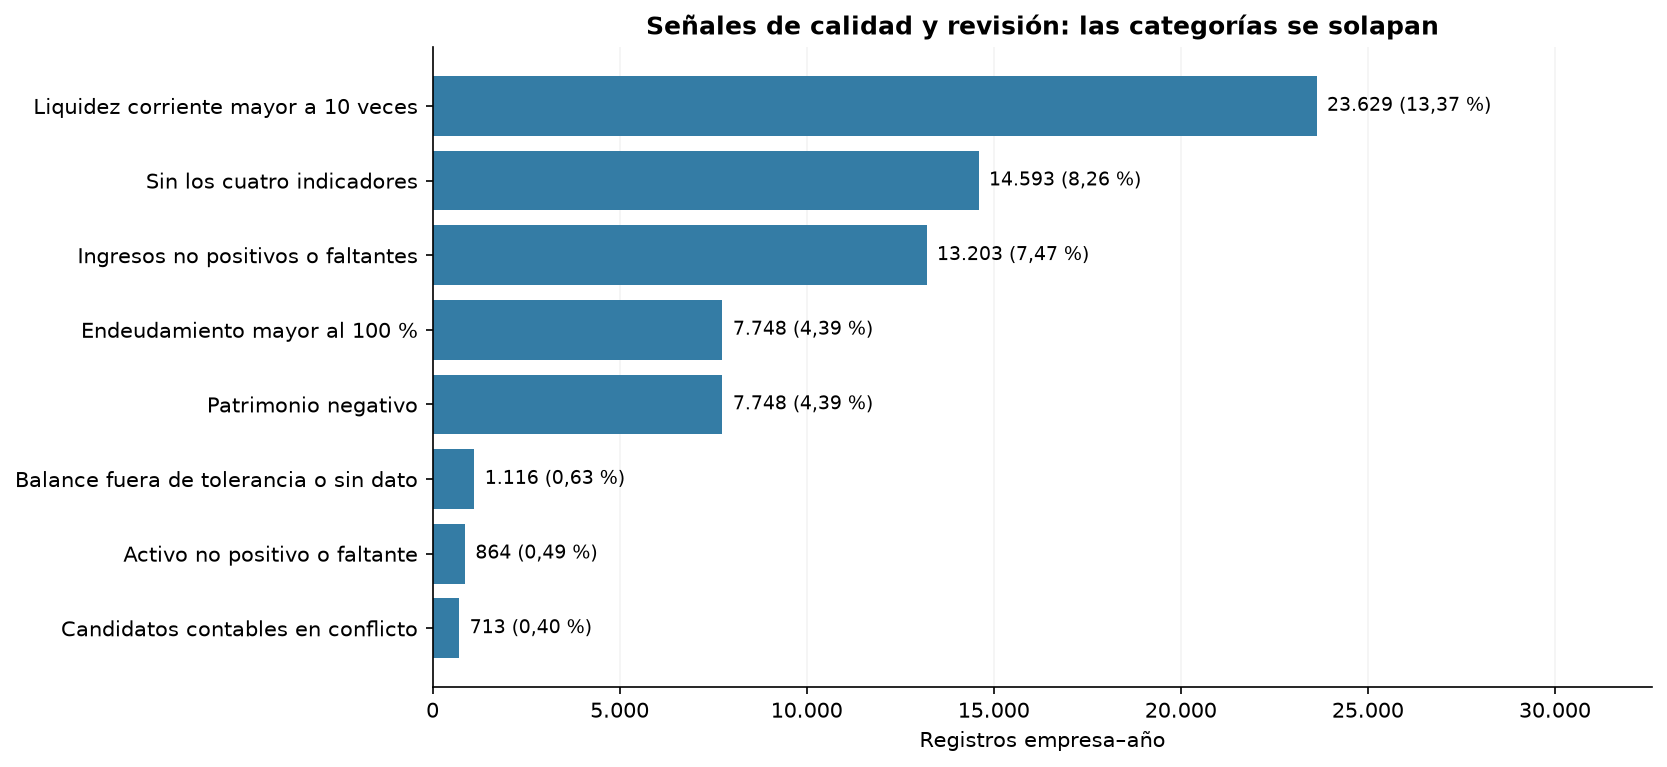

,incidencia,registros,porcentaje_recalculado
2,Candidatos contables en conflicto,713,0.40
3,Activo no positivo o faltante,864,0.49
1,Balance fuera de tolerancia o sin dato,1116,0.63
5,Patrimonio negativo,7748,4.39
7,Endeudamiento mayor al 100 %,7748,4.39
4,Ingresos no positivos o faltantes,13203,7.47
0,Sin los cuatro indicadores,14593,8.26
6,Liquidez corriente mayor a 10 veces,23629,13.37


In [7]:
issue_labels = {
    "sin_cuatro_indicadores": "Sin los cuatro indicadores",
    "balance_no_cuadra_o_sin_dato": "Balance fuera de tolerancia o sin dato",
    "con_candidatos_en_conflicto": "Candidatos contables en conflicto",
    "activo_total_no_positivo_o_faltante": "Activo no positivo o faltante",
    "ingresos_no_positivos_o_faltantes": "Ingresos no positivos o faltantes",
    "patrimonio_negativo": "Patrimonio negativo",
    "liquidez_corriente_mayor_a_10": "Liquidez corriente mayor a 10 veces",
    "endeudamiento_mayor_a_1": "Endeudamiento mayor al 100 %",
}
issues_view = issues.copy()
issues_view["incidencia"] = issues_view["tipo_incidencia"].map(issue_labels).fillna(issues_view["tipo_incidencia"])
issues_view["porcentaje_recalculado"] = 100 * issues_view["registros"] / TOTAL
issues_view = issues_view.sort_values("registros")
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
bars = ax.barh(issues_view["incidencia"], issues_view["registros"], color=PALETTE["blue"])
ax.bar_label(bars, labels=[f"{numero_es(r)} ({numero_es(p, 2)} %)" for r, p in zip(issues_view["registros"], issues_view["porcentaje_recalculado"])], padding=5, fontsize=9)
ax.set_xlim(0, issues_view["registros"].max() * 1.38)
ax.set(title="Señales de calidad y revisión: las categorías se solapan", xlabel="Registros empresa–año")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: numero_es(v)))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=.15)
mostrar_figura(fig, "03_incidencias")
display(issues_view[["incidencia", "registros", "porcentaje_recalculado"]].round(2))
guardar_tabla(issues_view, "incidencias_recalculadas")

La documentación previa declara **6.117 discrepancias NIT–año–variable**, distribuidas en **713 pares NIT–año**, y **271 discrepancias** con cociente máximo/mínimo cercano a 1.000 (entre 990 y 1.010). Tienen unidades diferentes. El agregado corrobora los 713 pares; los otros conteos son cifras declaradas en el TXT porque no recibimos el archivo de discrepancias.

La coincidencia de dos frecuencias, por ejemplo patrimonio negativo y endeudamiento mayor al 100 %, no prueba que correspondan a las mismas filas. Se necesitan los microdatos. No se corrige ninguna escala con estos resúmenes.

## 6. Razones financieras: medianas, dispersión y extremos

Los estadísticos recibidos pertenecen al **filtro descriptivo estricto**, no a todo el panel. Las bandas son percentiles publicados; no son intervalos de confianza ni distribuciones reconstruidas. Cada año puede contener empresas distintas.

Endeudamiento, ROA y margen se presentan en porcentaje; liquidez, en veces. No se calculan medianas globales promediando medianas anuales.

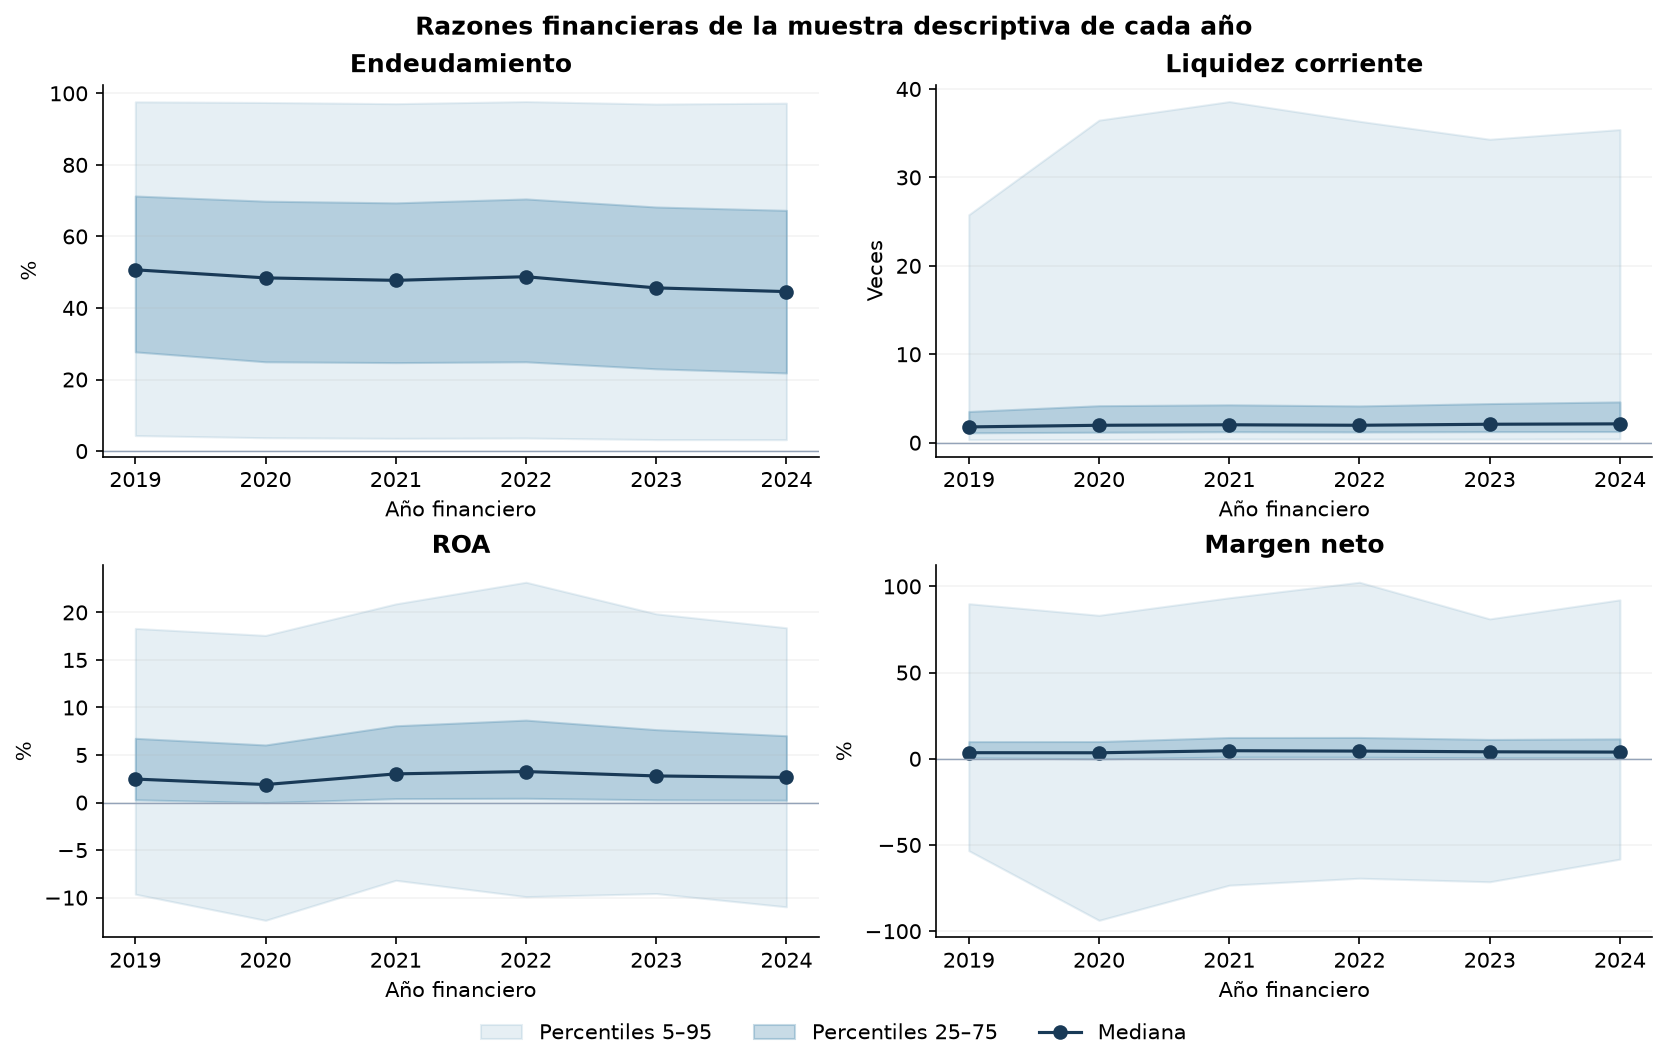

**Detalle de 2024; n corresponde al filtro estricto de ese año.**

,indicador,n,media,mediana,p05,p95,minimo,maximo,unidad
0,endeudamiento,27275,52.15,44.57,3.182,97.26,8.827e-05,4.686e+04,%
1,liquidez_corriente,27275,51.84,2.131,0.4276,35.41,0,3.77e+05,veces
2,roa,27275,1.662,2.647,-10.97,18.39,-1.235e+04,317.1,%
3,margen_neto,27275,2.017e+06,3.89,-58.2,92.2,-2.918e+07,3.714e+10,%


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for ax, variable in zip(axes.flat, INDICADORES):
    part = stats.loc[stats["indicador"].eq(variable)].sort_values("anio_financiero")
    factor = 1 if variable == "liquidez_corriente" else 100
    xx = part["anio_financiero"].to_numpy(dtype=int)
    values = {col: part[col].to_numpy(dtype=float) * factor for col in ["p05", "p25", "mediana", "p75", "p95"]}
    ax.fill_between(xx, values["p05"], values["p95"], alpha=.12, color=PALETTE["blue"], label="Percentiles 5–95")
    ax.fill_between(xx, values["p25"], values["p75"], alpha=.27, color=PALETTE["blue"], label="Percentiles 25–75")
    ax.plot(xx, values["mediana"], color=PALETTE["navy"], marker="o", label="Mediana")
    ax.axhline(0, color="#94A3B8", linewidth=.7)
    ax.set(title=ETIQUETAS[variable], xlabel="Año financiero", ylabel="Veces" if factor == 1 else "%")
    ax.set_xticks(xx)
    ax.grid(axis="y", alpha=.15)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3, frameon=False)
fig.suptitle("Razones financieras de la muestra descriptiva de cada año", fontweight="bold")
mostrar_figura(fig, "04_mediana_y_percentiles")

latest_year = int(stats["anio_financiero"].max())
latest = stats.loc[stats["anio_financiero"].eq(latest_year)].set_index("indicador").loc[INDICADORES].reset_index()
latest_view = latest[["indicador", "n", "media", "mediana", "p05", "p95", "minimo", "maximo"]].copy()
latest_view["unidad"] = latest_view["indicador"].eq("liquidez_corriente").map({True: "veces", False: "%"})
numeric_summary_columns = ["media", "mediana", "p05", "p95", "minimo", "maximo"]
for col in numeric_summary_columns:
    latest_view[col] = latest_view[col] * np.where(latest_view["unidad"].eq("%"), 100, 1)
display(Markdown(f"**Detalle de {latest_year}; n corresponde al filtro estricto de ese año.**"))
readable_latest = latest_view.copy()
for col in numeric_summary_columns:
    readable_latest[col] = readable_latest[col].map(lambda value: f"{value:.4g}")
display(readable_latest)
guardar_tabla(latest_view, "indicadores_ultimo_anio_presentacion")
guardar_tabla(stats, "estadisticos_recibidos")

In [9]:
wide_median = stats.pivot(index="anio_financiero", columns="indicador", values="mediana").sort_index()
first_year = int(wide_median.index.min())
first_debt = wide_median.loc[first_year, "endeudamiento"] * 100
last_debt = wide_median.loc[latest_year, "endeudamiento"] * 100
margin_latest = latest.set_index("indicador").loc["margen_neto"]
display(Markdown(f"""
**Lectura de los resúmenes**

- La mediana anual de endeudamiento pasa de **{numero_es(first_debt, 2)} %** en {first_year}
  a **{numero_es(last_debt, 2)} %** en {latest_year}: diferencia de
  **{numero_es(last_debt - first_debt, 2)} puntos porcentuales**. No es una comparación
  de panel balanceado ni demuestra una mejora del riesgo de las mismas empresas.
- En {latest_year}, la liquidez mediana es **{numero_es(wide_median.loc[latest_year, 'liquidez_corriente'], 2)} veces**,
  el ROA mediano es **{numero_es(100 * wide_median.loc[latest_year, 'roa'], 2)} %**
  y el margen neto mediano es **{numero_es(100 * wide_median.loc[latest_year, 'margen_neto'], 2)} %**.
- El margen neto del último año tiene media de **{numero_es(margin_latest['media'], 4)}**,
  mediana de **{numero_es(margin_latest['mediana'], 6)}** y máximo de
  **{numero_es(margin_latest['maximo'], 2)}**, en **razón original**.
  La separación evidencia sensibilidad a extremos. No permite distinguir una situación
  económica real de un denominador pequeño o un problema de unidad/reporte. Se necesitan
  las filas originales antes de transformar o eliminar valores.
"""))


**Lectura de los resúmenes**

- La mediana anual de endeudamiento pasa de **50,67 %** en 2019
  a **44,57 %** en 2024: diferencia de
  **-6,09 puntos porcentuales**. No es una comparación
  de panel balanceado ni demuestra una mejora del riesgo de las mismas empresas.
- En 2024, la liquidez mediana es **2,13 veces**,
  el ROA mediano es **2,65 %**
  y el margen neto mediano es **3,89 %**.
- El margen neto del último año tiene media de **20.170,7178**,
  mediana de **0,038901** y máximo de
  **371.411.533,00**, en **razón original**.
  La separación evidencia sensibilidad a extremos. No permite distinguir una situación
  económica real de un denominador pequeño o un problema de unidad/reporte. Se necesitan
  las filas originales antes de transformar o eliminar valores.


## 7. Cruce preliminar con insolvencia

El resumen del cruce corresponde a un corte mensual de octubre de 2026 y los archivos financieros originales. **Los conteos no están restringidos al panel 2019–2024** y no deben usarse como tasa de insolvencia de ese panel.

El código recibido compara años y reúne la unión de años disponibles de ambas fuentes por NIT; no exige ambos estados para el mismo NIT–año. Tampoco verifica publicación, primera admisión elegible o seguimiento suficiente.

,Alcance reportado,NIT (cruce preliminar)
0,NIT coincidentes con ambas fuentes financieras,2772
1,Con algún ejercicio financiero anterior,1756
2,Con algún ejercicio entre 1 y 3 años antes,1624


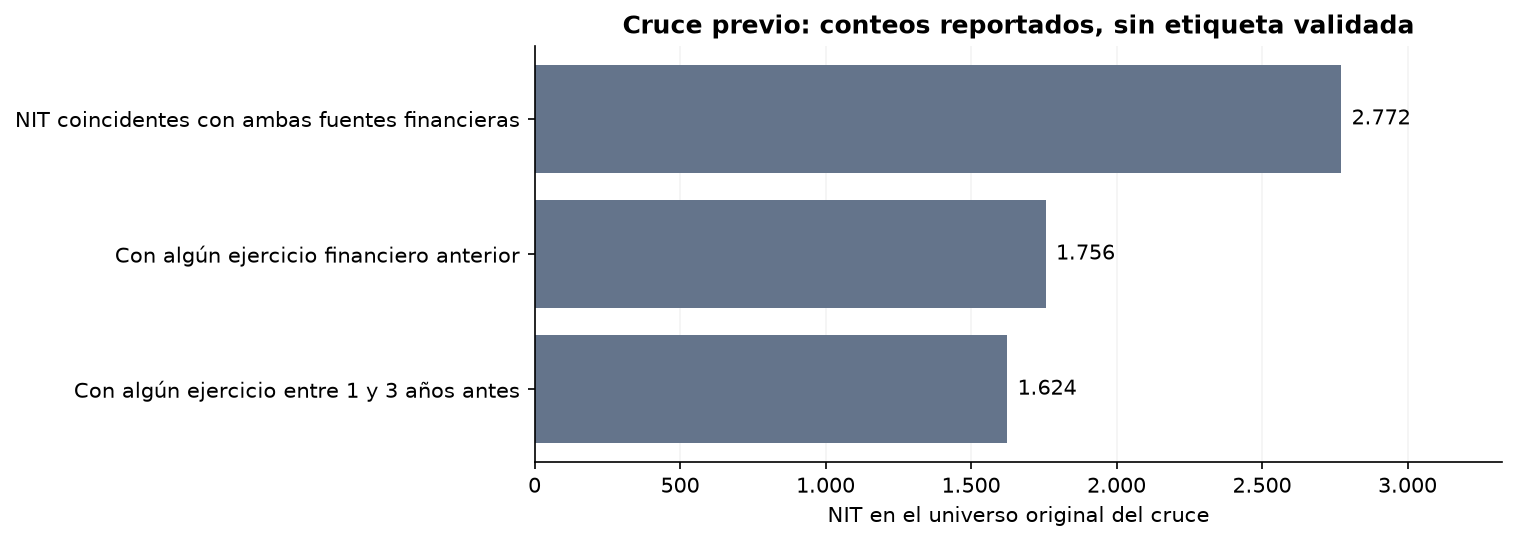

No son casos positivos validados a doce meses. Ausencia en un corte mensual no prueba una clase negativa.


In [10]:
def metrica_cruce(label):
    matches = crossing.loc[crossing["indicador"].eq(label), "valor"]
    if len(matches) != 1:
        raise ValueError(f"No hay una métrica inequívoca: {label}")
    return int(matches.iloc[0])

cross_rows = [
    ("NIT coincidentes con ambas fuentes financieras", "NIT insolvencia presentes en ambos estados financieros"),
    ("Con algún ejercicio financiero anterior", "Cruces con algun estado financiero de FECHA_CORTE previa al ano apertura (preliminar)"),
    ("Con algún ejercicio entre 1 y 3 años antes", "Cruces con FECHA_CORTE 1-3 anos antes del ano apertura (preliminar)"),
]
cross_view = pd.DataFrame([{"Alcance reportado": title, "NIT (cruce preliminar)": metrica_cruce(key)} for title, key in cross_rows])
display(cross_view)
fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
bars = ax.barh(cross_view["Alcance reportado"][::-1], cross_view["NIT (cruce preliminar)"][::-1], color=PALETTE["gray"])
ax.bar_label(bars, labels=[numero_es(v) for v in cross_view["NIT (cruce preliminar)"][::-1]], padding=5)
ax.set_xlim(0, cross_view["NIT (cruce preliminar)"].max() * 1.2)
ax.set(title="Cruce previo: conteos reportados, sin etiqueta validada", xlabel="NIT en el universo original del cruce")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: numero_es(v)))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=.15)
mostrar_figura(fig, "05_cruce_preliminar")
guardar_tabla(cross_view, "cruce_preliminar_reportado")
print("No son casos positivos validados a doce meses. Ausencia en un corte mensual no prueba una clase negativa.")

Para construir la futura variable objetivo debemos acordar proceso formal, primera admisión elegible, momento de evaluación, disponibilidad efectiva de cada estado e intervalo de seguimiento. La clase sin evento requiere seguimiento completo: la ausencia en un listado mensual no basta. Los nueve cortes mensuales tampoco representan nueve conjuntos independientes.

El NIT servirá para vincular fuentes y controlar particiones, no como predictor. La evaluación temporal debe evitar información posterior a la consulta y controlar la repetición de empresas entre particiones.

## 8. Ampliación opcional con la base individual

**Estado de esta ejecución: pendiente, archivo no recibido.**

Cuando el equipo recupere base_financiera_preliminar.csv, puede colocarla en data/privados/. La celda siguiente ejecutará auditoría de claves, nulos, conversiones, controles contables, estadísticos individuales, histogramas y correlaciones.

El módulo conserva los valores originales y diferencia todas las filas de un **filtro descriptivo auditado reforzado**. Este último incorpora controles adicionales de claves, duplicados y banderas desconocidas; no tiene por qué reproducir el conteo del filtro previo. No vuelve a consolidar los estados originales ni valida la etiqueta de insolvencia.

La carpeta privada se excluye de Git mediante .gitignore. No se presentan ni exportan identificadores individuales. Antes de compartir nuevos resultados se deben revisar su contenido y las condiciones de uso de los datos.

In [11]:
MICRODATA = ROOT / "data/privados/base_financiera_preliminar.csv"
microdata_result = None
if not MICRODATA.is_file():
    display(Markdown("**Pendiente:** no se recibió base_financiera_preliminar.csv. "
                     "No se calcularon duplicados por empresa, distribuciones individuales, correlaciones "
                     "ni nuevas etiquetas. Los resultados anteriores provienen exclusivamente de agregados."))
else:
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    from src.auditoria_microdatos import analizar_microdatos
    microdata_result = analizar_microdatos(MICRODATA, ROOT / "results/microdatos")
    display(Markdown("**Auditoría individual ejecutada con un archivo local adicional.** "
                     "Revise trazabilidad, advertencias y diferencias frente a los agregados previos."))
    display(pd.DataFrame([microdata_result["resumen"]]))
    for name, table in microdata_result["tablas"].items():
        display(Markdown(f"**{name}**"))
        display(table)
    for warning in microdata_result["advertencias"]:
        display(Markdown(f"- {warning}"))
    for path in microdata_result["graficos"].values():
        display(Image(filename=str(path)))

**Pendiente:** no se recibió base_financiera_preliminar.csv. No se calcularon duplicados por empresa, distribuciones individuales, correlaciones ni nuevas etiquetas. Los resultados anteriores provienen exclusivamente de agregados.

## 9. Hallazgos para la primera entrega y pendientes

Los resúmenes permiten sustentar tamaño del panel, porcentajes de calidad y evolución anual de razones financieras. No permiten verificar independencia, representatividad de todas las empresas colombianas ni capacidad predictiva.

| Tema | Estado | Acción siguiente |
| --- | --- | --- |
| Integridad y aritmética de agregados | Ejecutado | Revisar controles e interpretación conjuntamente |
| Tablas y figuras anuales | Ejecutado | Seleccionar las necesarias para el informe de máximo diez páginas |
| Consolidación y versiones contables | Pendiente de microdatos | Reconciliar NIT, radicado, taxonomía, ejercicio y unidades |
| Claves, nulos y distribuciones individuales | Código preparado; sin ejecución sobre datos reales | Recuperar base desde archivo verificable o remoto compartido |
| Cruce y etiqueta temporal | Preliminar, sin clases validadas | Acordar evento, horizonte, seguimiento y disponibilidad |
| Git y DVC | No se crean repositorios o remotos aquí | Crear repositorio y comprobar recuperación de datos |
| Contribuciones del equipo | Por confirmar | Registrar aportes reales y commits |

Las distribuciones y correlaciones individuales son parte de una EDA completa y **quedan pendientes**. Este paquete permite explorar de forma reproducible los agregados recibidos. Entrenamiento, evaluación predictiva, MLflow, API y contenedores corresponden a fases posteriores.

In [12]:
# Manifiesto sin rutas personales ni identificadores.
execution_manifest = {
    "alcance": "Exploración de agregados recibidos; no reproducción de la consolidación original",
    "periodo_financiero": [int(coverage["anio_financiero"].min()), int(coverage["anio_financiero"].max())],
    "observaciones_empresa_anio": TOTAL,
    "muestra_descriptiva_estricta": STRICT,
    "empresas_unicas_declaradas_no_recalculadas": unique_reported,
    "insumos": manifest.astype(object).where(pd.notna(manifest), None).to_dict(orient="records"),
    "versiones": versiones,
    "controles_agregados_cumplen": bool(checks["cumple"].all()),
    "base_individual_presente": MICRODATA.is_file(),
    "auditoria_individual_ejecutada": microdata_result is not None,
    "etiqueta_insolvencia_validada": False,
    "modelo_entrenado": False,
    "figuras_agregadas": [p.name for p in sorted(FIGURES.glob("*.png"))],
}
(ROOT / "results/manifiesto_ejecucion.json").write_text(json.dumps(execution_manifest, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print(f"Ejecución completada: {len(checks)} controles internos, {len(execution_manifest['figuras_agregadas'])} figuras de agregados.")
print("Resultados guardados en results/. Revise README.md para reproducir el cuaderno y organizar GitHub.")

Ejecución completada: 8 controles internos, 5 figuras de agregados.
Resultados guardados en results/. Revise README.md para reproducir el cuaderno y organizar GitHub.


## Referencias y procedencia

- Cuatro CSV y dos TXT de 05_RESULTADOS_AGREGADOS/ de FINRISK.zip compartido por el equipo. Las huellas se registran en la sección 2.
- Definición del filtro y estadísticos: finrisk_etapa5_exploratorio_corregido.py, recibido en 06_CODIGO/. Se interpretan sus salidas sin ejecutar el script original.
- Límites del cruce: finrisk_validar_cruce.py y resumen_cruce.csv, recibidos con el mismo paquete. No se generó aquí un nuevo cruce.
- Guía y rúbrica de la primera entrega aportadas por Joaquín. El notebook es un soporte y no reemplaza el informe ni acredita aprobación conjunta o aportes no confirmados.

El cuaderno incorpora verificaciones, tablas, gráficos y explicaciones preparados con asistencia de Codex para revisión de Joaquín y del equipo. Los agregados originales se atribuyen a los avances recibidos de FINRISK, no a una nueva ejecución individual. No se fabrican datos, predicciones o evidencias de Git/DVC.